**Задание 1: Сбор датасета**

По началу думал над тем, чтобы собрать датасет из моих добавленных треков в Вк музыке. Но разбираться с апишкой оказалось очень долго + прямых ссылок на трек нет. Поэтому мной было принято решение найти открытый плейлист по современному афро-хаус жанру в Youtube music, думаю должно так же хорошо подойти для следующих заданий.

In [23]:

!pip install yt-dlp pandas
import yt_dlp
import pandas as pd

playlist_url = 'https://music.youtube.com/playlist?list=RDCLAK5uy_lakBT61ImX7CpKwUjDyQGGY-K7v1GSZwM'

ydl_opts = {
    'extract_flat': True,
    'playlistend': 60, #соберем 60 треков
    'quiet': True
}

dataset = []
print("собираем данные из плейлиста")
with yt_dlp.YoutubeDL(ydl_opts) as ydl:
    info = ydl.extract_info(playlist_url, download=False)
    if 'entries' in info:
        for entry in info['entries']:
            if entry:
                dataset.append({
                    'title': entry.get('title', 'Unknown Title'),
                    'artist': entry.get('channel', 'Unknown Artist'),
                    'duration_sec': entry.get('duration', 0),
                    'audio_link': f"https://www.youtube.com/watch?v={entry.get('id')}"
                })

df = pd.DataFrame(dataset)
display(df.head())

собираем данные из плейлиста


,title,artist,duration_sec,audio_link
0,Jamaican (Bam Bam),HUGEL,157,https://www.youtube.com/watch?v=i34pFNr42mc
1,Move,Adam,178,https://www.youtube.com/watch?v=j1QrD9-S4sU
2,"Francis Mercier, Magic System, Chawki - Magic ...",Francis Mercier,168,https://www.youtube.com/watch?v=wWSkLPPIslY
3,Shimza & Demayä - Sunset in Pretoria (Official...,SHIMZA,475,https://www.youtube.com/watch?v=XrOBMH1KjO0
4,"Jason Derulo, The Second Voice, Qing Madi - LE...",Jason Derulo,171,https://www.youtube.com/watch?v=Jc4bu_a-vi0


источник данных-это плейлист из YouTube Music. данные собиралисб через библиотеку yt-dlp.

отбор треков-это готовая подборка от ютуб по афрохаус, треки выгружались подряд с 1 по 60.

жанр- Современный Afro House.

из ограничений только ограничение выборки в 60 треков. лимиты по количеству треков на конкретного артиста специально не делал, чтобы сохранить разнообразие плейлиста + афро хаус это вообще не про исполнителей.

**Задание 2: Формирование набора признаков**

для грамотного формирования фичей требуются как мне кажется знания теории музыки (понимание ритма, динамики, тональности) и специфики конкретного жанра. а так как современный афро хаус имеет ярко выраженные звуковые особенности поэтому для точной валидации музыкальных параметров я решил что самый лучший вариант это будет пообщаться с нейронкой.

решил раскидать набор признаков на две категории. описывающие звук и не описывающие звук напрямую.

1. Звук

Темп (удары в минуту)- это про то насколько трек быстрый или медленный.
полезность для рекомендаций: в афро-хаусе, но и абсолютно но всех жанрах скорость ритма решает всё. так как например если алгоритм включит очень быстрый трек сразу после спокойного, это собьет слушателя.

Настроение звучания(энергичность)для оценки того, музыка бодрящая или расслабляющая. хоть и афро хаус подразумевает под собой что то танцевальное все таки у него бывают разновидности и это тоже стоит учесть.
полезность для рекомендаций: этот признак нужен, чтобы система подстраивалась под состояние слушателя и не ломала его настроение, предлагая громкий танцевальный трек во время например спокойного фонового прослушивания.

2. Теперь не звук

Векторные аудио-эмбеддинги это превращение трека в набор цифр с помощью нейросети.(так как компьютер не может слышать музыку как человек)
полезность для рекомендаций: мы переводим вайб трека на язык машины, это позволяет алгоритму находить неочевидные связи и рекомендовать треки, которые просто звучат в похожем стиле. один из важных признакоы которы всегд стоит учитывать, хоть и не всегда может быть точно работующим.

ну и Популярность (кол во просмотров/прослушиваний)

полезность для рекомендаций:вообще это социальный признак, который помогает алгоритму соблюдать баланс. когда-то предложить слушателю очень популярный хит, а когда-то подкинуть хорошего, но малоизвестного артиста для расширения музыкального кругозора.
хоть этот признак может показаться очень базовым и не очень полезным, на самом деле он очень важен и очень круто рзнообразит музыкальную волну.

вообще можно очень долго придумывать и выделять разные признаки. поэтому, так как это всего лишь тестовое задание остановимся пока что на этом.

**Задание 3: Извлечение признаков**

In [24]:
import os
import librosa
import numpy as np
from tqdm import tqdm

def track_features(url, idx):
    temp_filename = f"temp_track_{idx}.mp3"
    ydl_opts = {'format': 'bestaudio/best','outtmpl': f"temp_track_{idx}.%(ext)s",'download_ranges': yt_dlp.utils.download_range_func(None, [(60, 90)]), #вырезаем 30 секунд
        'postprocessors': [{'key': 'FFmpegExtractAudio','preferredcodec': 'mp3', 'preferredquality': '128',}],
        'quiet': True,
        'no_warnings': True}

    try:
        with yt_dlp.YoutubeDL(ydl_opts) as ydl: #достаем просмотры
            info = ydl.extract_info(url, download=True)
            views = info.get('view_count', 0)

        y, sr = librosa.load(temp_filename, sr=22050)
        tempo, _ = librosa.beat.beat_track(y=y, sr=sr) #темп
        bpm = float(np.ndim(tempo) and tempo[0] or tempo)
        rms = librosa.feature.rms(y=y) #энергичность
        energy = float(np.mean(rms))

        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)#аудио эмбеддинг
        mfcc_vector = np.mean(mfcc.T, axis=0).round(3).tolist()
        if os.path.exists(temp_filename):
            os.remove(temp_filename)
        return views, round(bpm, 1), round(energy, 4), mfcc_vector

    except Exception as e:
        if os.path.exists(temp_filename):
            os.remove(temp_filename)
        return None, None, None, None

views_list, bpm_list, energy_list, embeddings_list = [], [], [], []

for idx, row in tqdm(df.iterrows(), total=len(df)):#для отслеживания загруженных треков
    v, b, e, emb = track_features(row['audio_link'], idx)
    views_list.append(v)
    bpm_list.append(b)
    energy_list.append(e)
    embeddings_list.append(emb)


df['bpm'] = bpm_list
df['energy'] = energy_list
df['views'] = views_list
df['audio_embedding'] = embeddings_list

df_enriched = df.dropna(subset=['bpm']).reset_index(drop=True)
print(f"\n обогащено треков: {len(df_enriched)}")
display(df_enriched.head())

  0%|          | 0/60 [00:00<?, ?it/s]

  2%|▏         | 1/60 [00:05<05:53,  5.99s/it]

  3%|▎         | 2/60 [00:11<05:32,  5.73s/it]

  5%|▌         | 3/60 [00:15<04:31,  4.77s/it]

  7%|▋         | 4/60 [00:19<04:06,  4.41s/it]

...

 97%|█████████▋| 58/60 [03:39<00:07,  3.79s/it]

 98%|█████████▊| 59/60 [03:42<00:03,  3.71s/it]

100%|██████████| 60/60 [03:46<00:00,  3.77s/it]


 обогащено треков: 60


,title,artist,duration_sec,audio_link,bpm,energy,views,audio_embedding
0,Jamaican (Bam Bam),HUGEL,157,https://www.youtube.com/watch?v=i34pFNr42mc,123.0,0.2686,171100646,"[-67.26699829101562, 83.18699645996094, -14.72..."
1,Move,Adam,178,https://www.youtube.com/watch?v=j1QrD9-S4sU,117.5,0.2565,161139607,"[-66.92900085449219, 90.81199645996094, 30.045..."
2,"Francis Mercier, Magic System, Chawki - Magic ...",Francis Mercier,168,https://www.youtube.com/watch?v=wWSkLPPIslY,123.0,0.1746,1222977,"[-62.529998779296875, 72.38700103759766, 6.065..."
3,Shimza & Demayä - Sunset in Pretoria (Official...,SHIMZA,475,https://www.youtube.com/watch?v=XrOBMH1KjO0,123.0,0.2251,181284,"[-78.13500213623047, 61.082000732421875, -11.5..."
4,"Jason Derulo, The Second Voice, Qing Madi - LE...",Jason Derulo,171,https://www.youtube.com/watch?v=Jc4bu_a-vi0,112.3,0.1772,1097099,"[-95.10299682617188, 82.21700286865234, 6.2309..."


библиотеки:yt-dlp юзалась для парсинга метаданных и скачивания аудио.
FFmpeg использовался для вырезки нужного куска и конвертации в mp3.
librosa: методы beat_track, rms и mfcc.

про подход:
очень оптимально с точки зрения экономии ресурсов и времени.так как треки афро хаус могут длятся по 6–8 минут скачивать 60 полных аудиофайлов очень долго и рискованно. поэтому было принято рещение настроить вырезку 30 сек фрагмента(с 60 по 90 секудну достаточно оптимально)
для стабильности решил конвертировать все в mp3 дабы избежать конфоиктов форматов + так просто удобнее.
MFCC оч круто и легко передает тембральную часть музыки для машины без лишней вычислительной сложности.

рассматривался вариант глубокого обучение для эмбеддингов(Hugging Face) чтобы получить более сложные эмбеддинги.но я пообщался с нейрокной и пришел к выводу, что для тестовго это перебор так как модели требуют достаточно gpu, долго инициализируются еще и замедляют пайплайн, а mfcc в целом и так достаточно.

**Задание 4: Анализ данных (EDA)**

In [25]:
top_track = df_enriched.loc[df_enriched['views'].idxmax()]
print(f"самый популярный трек {top_track['artist']} - {top_track['title']} ({int(top_track['views']):,} просмотров)")
fast_track = df_enriched.loc[df_enriched['bpm'].idxmax()]
print(f"самый быстрый трек {fast_track['artist']} - {fast_track['title']} ({fast_track['bpm']} bpm)")
dense_track = df_enriched.loc[df_enriched['energy'].idxmax()]
print(f"самый энергичный трек {dense_track['artist']} - {dense_track['title']} (energyy {dense_track['energy']})")

самый популярный трек HUGEL - Jamaican (Bam Bam) (171,100,646 просмотров)
самый быстрый трек HoneyLuv - This Is My Life (Bontan Extended Mix) (172.3 bpm)
самый энергичный трек TOM ENZY - Nobody (energyy 0.3915)


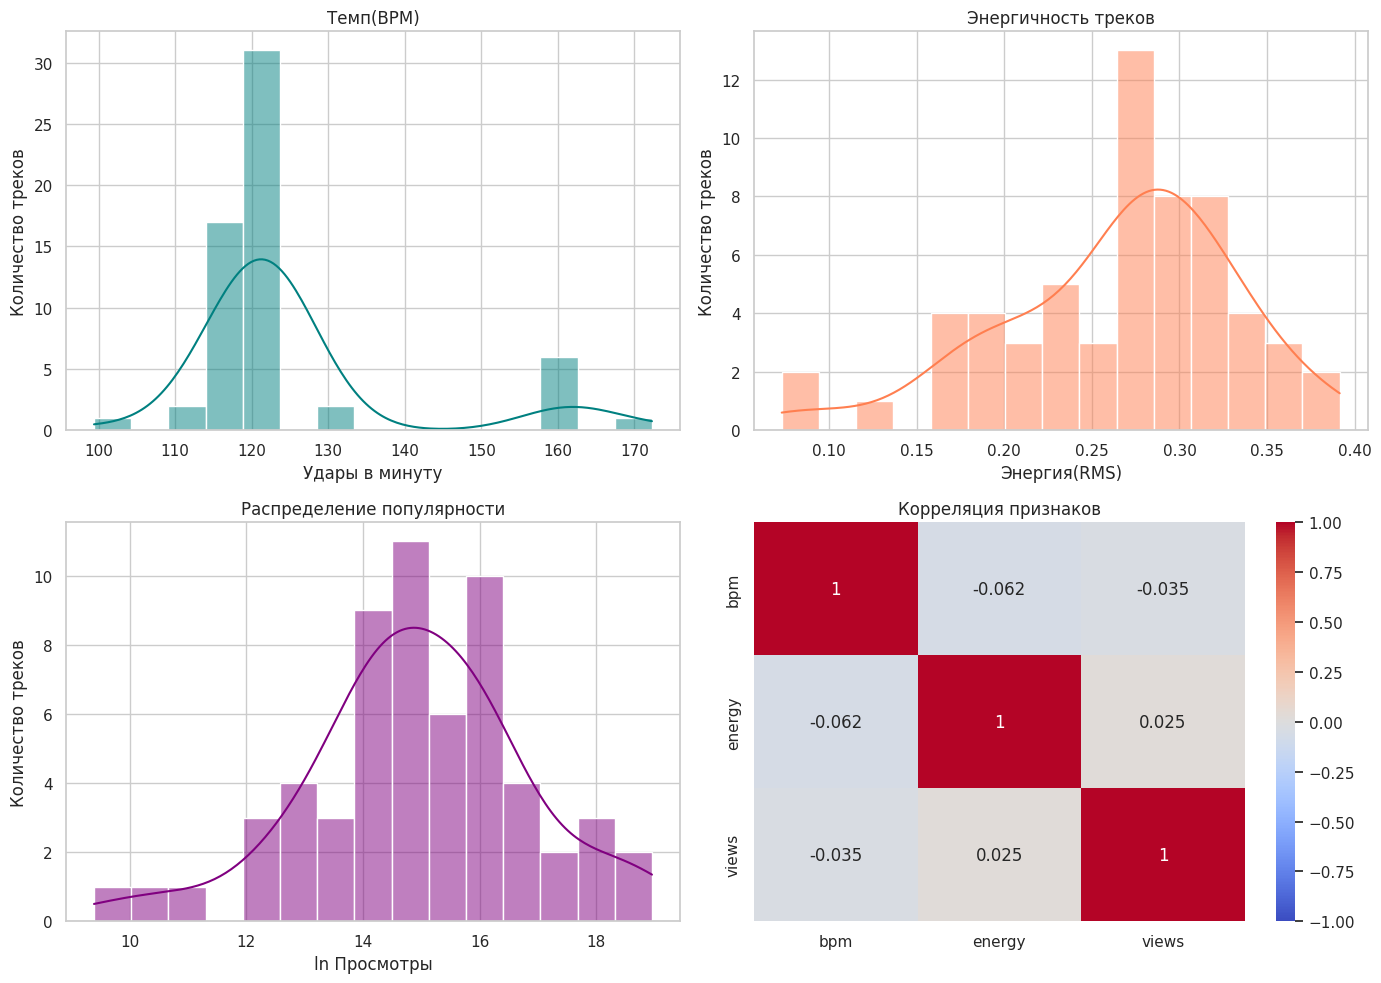

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_enriched['bpm'], kde=True, bins=15, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Темп(BPM)')
axes[0, 0].set_xlabel('Удары в минуту')
axes[0, 0].set_ylabel('Количество треков')

sns.histplot(df_enriched['energy'], kde=True, bins=15, ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Энергичность треков')
axes[0, 1].set_xlabel('Энергия(RMS)')
axes[0, 1].set_ylabel('Количество треков')

sns.histplot(np.log1p(df_enriched['views']), kde=True, bins=15, ax=axes[1, 0], color='purple')
axes[1, 0].set_title('Распределение популярности')
axes[1, 0].set_xlabel('ln Просмотры') #чтобы не руинить график(сжать разброс)
axes[1, 0].set_ylabel('Количество треков')

corr_cols = ['bpm', 'energy', 'views']
sns.heatmap(df_enriched[corr_cols].corr(), annot=True, cmap='coolwarm', ax=axes[1, 1], vmin=-1, vmax=1)
axes[1, 1].set_title('Корреляция признаков')

plt.tight_layout()
plt.show()

график темпа наглядно подтверждает жанровые рамки афро-хауса. основная масса треков сгруппирована в общепринятый стандарт скорости под который людям комфортно танцевать, а диджеям легко сводить треки. это очень хорошо доказывает мою теорию о схожести темпа в самом начале задания.
так же распредление энергии показывает нам то, что создатели плейлиста сделали упор на танцевальное звучание.
логарифм просмотров в нормальном распределении.
что было и логично, тепловая матрица выявила нулевую связь между всеми признаками.

**Задание 5:Эксперименты с представлением треков**

для построения рекомендательной системы сведем все извлеченные аудиопризнаки в единое целое.далее формируем массив и очищаем от шума.для описания звука возьмем темп, энергию и 13 коэффициентов тембра mfcc. просмотры специально уберем из модели так как алгоритм может заигнорить реальное звучание музыки и подбирать только популярные треки.
в модели похожести треков будем юзать косинусное сходство.


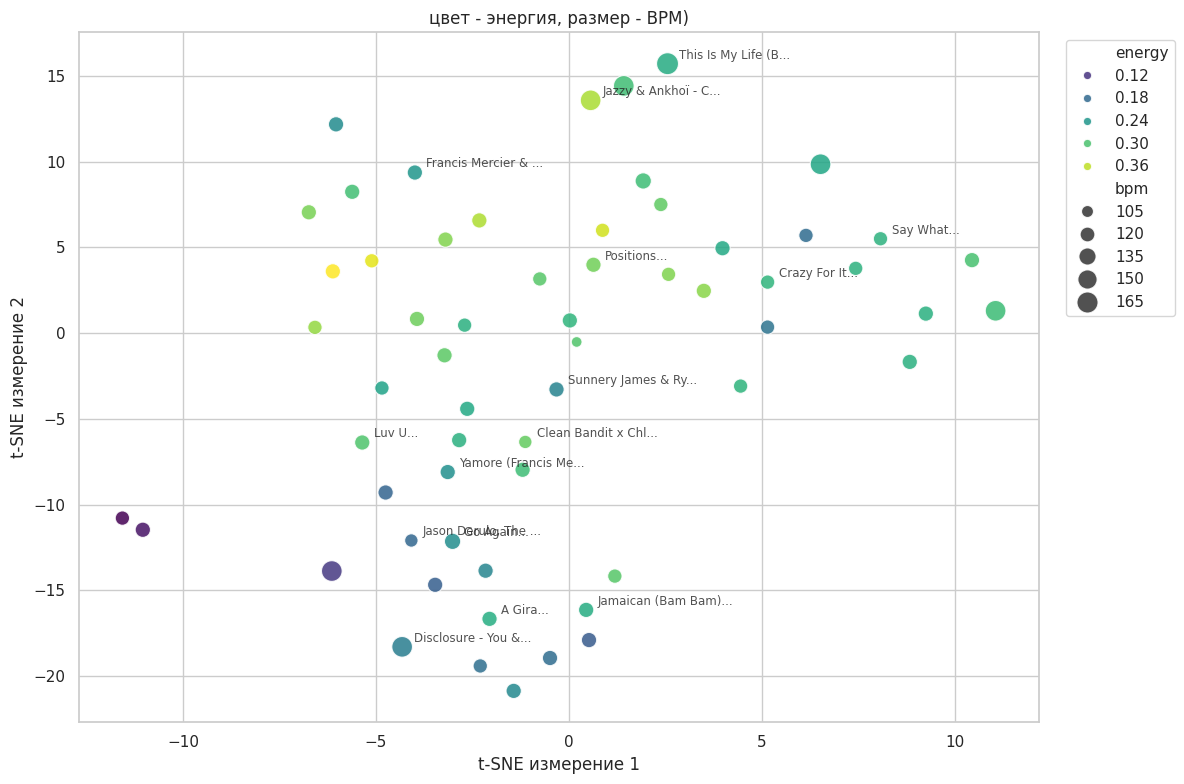

пример работы

исходный трек [3]: SHIMZA - Shimza & Demayä - Sunset in Pretoria (Official Audio)
параметры BPM = 123.0 | энергия = 0.2251


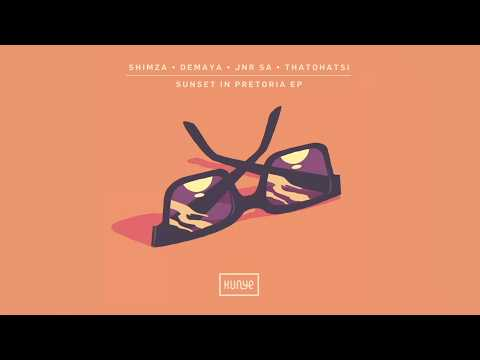



топ ближайших треков по звучаниюю:

1. Topic - TIK TAK (сходство: 0.509)
 параметры  BPM = 123.0 | энергия = 0.2806


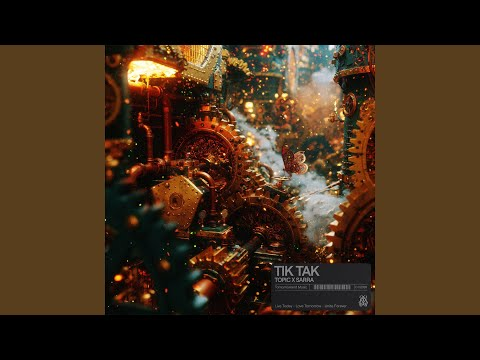

--------------------------------------------------
2. Francis Mercier - Yamore (Francis Mercier & Andre Soueid Remix) (сходство: 0.488)
 параметры  BPM = 123.0 | энергия = 0.2319


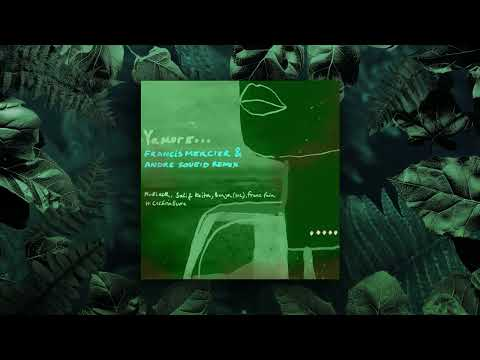

--------------------------------------------------
3. Francis Mercier - Francis Mercier & Magic System - Premier Gaou (Nitefreak Remix) - Official Music Video (сходство: 0.438)
 параметры  BPM = 123.0 | энергия = 0.2393


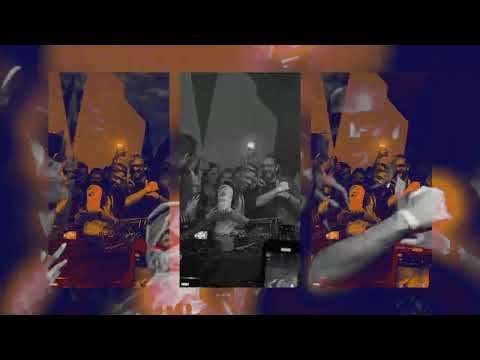

--------------------------------------------------


In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from IPython.display import YouTubeVideo, display

mfcc_matrix = np.array(df_enriched['audio_embedding'].tolist()) #создаем список
mfcc_df = pd.DataFrame(mfcc_matrix, columns=[f'mfcc_{i+1}' for i in range(13)])

features_df = pd.concat([df_enriched[['bpm', 'energy']].reset_index(drop=True), mfcc_df], axis=1)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_df)
similarity_matrix = cosine_similarity(features_scaled)

tsne = TSNE(n_components=2, perplexity=10, random_state=42)
embeddings_2d = tsne.fit_transform(features_scaled)
df_enriched['tsne_x'] = embeddings_2d[:, 0]
df_enriched['tsne_y'] = embeddings_2d[:, 1]

plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(
    data=df_enriched,
    x='tsne_x', y='tsne_y',
    hue='energy', size='bpm',
    sizes=(60, 250), palette='viridis', alpha=0.85
)

for i in range(0, len(df_enriched), 4): #график похожести
    plt.text(
        df_enriched['tsne_x'].iloc[i] + 0.3,
        df_enriched['tsne_y'].iloc[i] + 0.3,
        df_enriched['title'].iloc[i][:18] + "...",
        fontsize=8.5, alpha=0.8
    )

plt.title('цвет - энергия, размер - BPM)')
plt.xlabel('t-SNE измерение 1')
plt.ylabel('t-SNE измерение 2')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

def get_yt_id(url): #вытаскиваем видосы для удобства оценки
    if pd.isna(url): return None
    return url.split('v=')[-1][:11] if 'v=' in url else None
def get_similar_tracks(track_idx, top_n=3):
    base_track = df_enriched.iloc[track_idx]
    print(f"исходный трек [{track_idx}]: {base_track['artist']} - {base_track['title']}")
    print(f"параметры BPM = {base_track['bpm']} | энергия = {base_track['energy']}")

    base_id = get_yt_id(base_track['audio_link'])
    if base_id: display(YouTubeVideo(base_id, width=320, height=180))
    print("\n" + "="*50 + "\n")

    sim_scores = list(enumerate(similarity_matrix[track_idx]))#считаем похожесть
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:top_n+1]

    print("топ ближайших треков по звучаниюю:\n")
    for rank, (idx, score) in enumerate(sim_scores, 1):
        rec = df_enriched.iloc[idx]
        print(f"{rank}. {rec['artist']} - {rec['title']} (сходство: {score:.3f})")
        print(f" параметры  BPM = {rec['bpm']} | энергия = {rec['energy']}")

        rec_id = get_yt_id(rec['audio_link'])
        if rec_id: display(YouTubeVideo(rec_id, width=320, height=180))
        print("-" * 50)

#тестируем на любых треках
print("пример работы\n")
get_similar_tracks(3, top_n=3) #берем четвертый тре

выводы: извлечение аудиопризнаков которые я взял отлично работает для создания рекомендаций по принципу диджейского свидения. в тестовом примере алгоритм подобрал оч хорошие варианты для микса: все рекомендованные треки имеют строго идентичный темп и максимально близкую акустическую плотность. так же можно прослушать треки самому и убедиться  визуализация t-SNE подтверждает логику вектора, алгоритм успешно сгруппировал треки.   
Ограничения и выявленные проблемы: невысокие показатели косинусного сходства показывают, что базовых математических признаков недостаточно, чтобы уловить тональность, наличие вокала или мелодическое настроение трека.проблема коротких фрагментов (с 60 по 90) для того чтобы экономит память.